# Giorno 3 — Modelli supervisionati: regressione, modelli lineari e SVM

> Linguaggio degli esempi: Python 3 (scikit-learn ≥ 1.4, NumPy, pandas, matplotlib). Ogni modulo segue la struttura: Spiegazione teorica → Esempi teorici di utilizzo → Esempi di codice → Esercizi.
> Prerequisiti dai giorni precedenti: API fit/predict/score, train/test split, overfitting e underfitting, scaling e regola d'oro del preprocessing, metriche di classificazione.

# 3.1 Regressione lineare

## Spiegazione teorica

**Obiettivo:** prevedere un **numero continuo** (prezzo, consumo, punteggio) a partire da una o più feature, assumendo che la relazione sia (approssimativamente) una **retta**.

**Regressione lineare semplice (una feature)**
- Modello: `ŷ = w · x + b`
  - `ŷ` ("y cappello") è il valore **previsto**;
  - `w` è il **coefficiente** (pendenza): di quanto cambia ŷ quando x aumenta di 1;
  - `b` è l'**intercetta**: il valore di ŷ quando x = 0.
- Esempio: `prezzo = 3000 · metri_quadri + 20000` → ogni metro quadro in più aggiunge 3000 € al prezzo stimato.

**Regressione lineare multipla (più feature)**
- Modello: `ŷ = w₁·x₁ + w₂·x₂ + … + wₙ·xₙ + b`
- Con 2 feature la "retta" diventa un piano, con più feature un **iperpiano** (lo stesso concetto in più dimensioni).
- Ogni coefficiente indica l'effetto di quella feature **a parità delle altre**.

**Come impara: i minimi quadrati**
- **Residuo:** la differenza tra valore reale e valore previsto, `y − ŷ`, per ogni campione.
- L'algoritmo sceglie w e b che rendono **minima la somma dei residui al quadrato**.
- Perché al quadrato: così errori positivi e negativi non si annullano e gli errori grandi pesano di più.
- In scikit-learn i parametri appresi sono `coef_` (un coefficiente per feature) e `intercept_`.

**Leggere i coefficienti**
- Segno: positivo → la feature fa aumentare la previsione; negativo → la fa diminuire.
- Grandezza: dipende dalle **unità di misura**. Per confrontare l'importanza di feature diverse bisogna prima standardizzarle.

**Relazioni non lineari: `PolynomialFeatures`**
- Se i dati seguono una curva, si possono aggiungere come nuove feature le **potenze** di quelle esistenti (x², x³…). Il modello resta lineare nei coefficienti ma può disegnare curve.
- `degree` controlla la potenza massima: grado troppo basso → underfitting; grado troppo alto → la curva insegue il rumore (overfitting).

**Parametri di `LinearRegression`**
- `fit_intercept` (default True): se False, l'intercetta è forzata a 0.
- `copy_X` (default True): lavora su una copia dei dati.
- `n_jobs`: numero di processori (-1 = tutti).
- Il parametro `normalize` citato in vecchi tutorial è stato **rimosso**: si usa `StandardScaler`.

## Esempi teorici di utilizzo

- **Immobiliare:** stima del prezzo in base a superficie, numero di stanze, distanza dal centro; i coefficienti dicono quanto "vale" ogni fattore.
- **Vendite:** quante unità si venderanno in funzione del budget pubblicitario e del prezzo.
- **Energia:** consumo elettrico di un edificio in funzione della temperatura esterna (spesso con un termine quadratico, perché si consuma sia con molto caldo sia con molto freddo).
- **Modello di riferimento:** prima di provare modelli complessi si addestra sempre una regressione lineare, veloce e interpretabile, come base di confronto.

## Esempi di codice

### Base
Cosa mostra: una regressione semplice e il significato di coefficiente e intercetta.

In [2]:
import numpy as np
from sklearn.linear_model import LinearRegression

metri = np.array([[40], [55], [70], [85], [100], [120]])          # X in 2D: una colonna
prezzo = np.array([140_000, 185_000, 230_000, 270_000, 320_000, 380_000])

modello = LinearRegression().fit(metri, prezzo)
print("Coefficiente w:", round(modello.coef_[0]))                # € per ogni m² in più
print("Intercetta b:", round(modello.intercept_))                 # prezzo "base" con 0 m²
print("Previsione 90 m²:", round(modello.predict([[90]])[0]))

# Verifica a mano: ŷ = w·x + b
print("A mano:", round(modello.coef_[0] * 90 + modello.intercept_))

Coefficiente w: 2992
Intercetta b: 19769
Previsione 90 m²: 289077
A mano: 289077


- `coef_` è un array (un valore per feature); qui c'è una sola feature, quindi `coef_[0]`.
- La previsione è esattamente `w · 90 + b`: il modello è solo questa formula.
- L'intercetta non va presa alla lettera (una casa di 0 m² non esiste): serve a posizionare la retta.

### Intermedio
Cosa mostra: regressione multipla sul dataset Diabetes e lettura dei coefficienti.

In [3]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

data = load_diabetes(as_frame=True)
X, y = data.data, data.target                        # y = progressione della malattia dopo un anno
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

modello = LinearRegression().fit(X_train, y_train)

coefficienti = pd.Series(modello.coef_, index=X.columns).sort_values()
print(coefficienti.round(1))                         # effetto di ogni feature
print("R² sul test:", round(modello.score(X_test, y_test), 3))   # score dei regressori = R² (modulo 3.2)

s1    -931.5
sex   -242.0
age     37.9
s6      48.7
s3     163.4
s4     275.3
bp     347.7
s2     518.1
bmi    542.4
s5     736.2
dtype: float64
R² sul test: 0.453


- In questo dataset le feature sono già centrate e scalate, quindi i coefficienti sono confrontabili tra loro.
- `bmi` (indice di massa corporea) e `s5` hanno i coefficienti positivi più alti: sono i fattori più legati alla progressione.
- Il punteggio (circa 0.45) dice che il modello spiega meno della metà della variabilità: i dati clinici disponibili non bastano per previsioni precise.

### Avanzato
Cosa mostra: `PolynomialFeatures` per modellare una curva, e cosa succede con un grado troppo basso o troppo alto.

grado  1: R² train=0.51  test=0.65
grado  4: R² train=0.92  test=0.83
grado 15: R² train=0.95  test=0.46


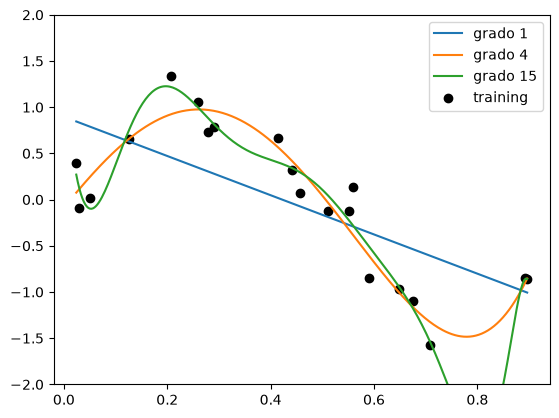

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

rng = np.random.RandomState(3)
x = np.sort(rng.uniform(0, 1, 20)).reshape(-1, 1)            # 20 punti di training
y = np.sin(2 * np.pi * x).ravel() + rng.normal(0, 0.25, 20)    # curva + rumore
x_test = rng.uniform(x.min(), x.max(), 200).reshape(-1, 1)     # dati nuovi nello stesso intervallo
y_test = np.sin(2 * np.pi * x_test).ravel() + rng.normal(0, 0.25, 200)

griglia = np.linspace(x.min(), x.max(), 300).reshape(-1, 1)
for grado in [1, 4, 15]:
    poly = PolynomialFeatures(degree=grado, include_bias=False)  # x -> x, x², ..., x^grado
    X_poly = poly.fit_transform(x)
    modello = LinearRegression().fit(X_poly, y)
    r2_train = modello.score(X_poly, y)
    r2_test = modello.score(poly.transform(x_test), y_test)
    print(f"grado {grado:2d}: R² train={r2_train:.2f}  test={r2_test:.2f}")
    plt.plot(griglia, modello.predict(poly.transform(griglia)), label=f"grado {grado}")

plt.scatter(x, y, color="k", label="training")
plt.ylim(-2, 2); plt.legend(); plt.show()

- Grado 1: una retta non può seguire un'onda → R² basso ovunque (underfitting).
- Grado 4: la curva segue la forma dei dati → buon risultato anche sul test.
- Grado 15: la curva si contorce per passare vicino a ogni punto → training più alto, test molto più basso (overfitting).
- `include_bias=False` evita di aggiungere una colonna di 1, perché l'intercetta la gestisce già `LinearRegression`.

## Esercizi

### Facile
Obiettivo: con i dati `temperatura = [18, 21, 24, 27, 30, 33]` e `gelati_venduti = [120, 150, 190, 230, 260, 310]`, addestra una regressione lineare, stampa coefficiente e intercetta e scrivi in italiano cosa significa il coefficiente. Prevedi le vendite a 29 °C.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: carica `fetch_california_housing(as_frame=True)` (richiede connessione), dividi 80/20 e addestra una regressione lineare. Stampa i coefficienti ordinati e confronta quelli ottenuti con e senza `StandardScaler` (fit sul training): quale feature sembra più importante nei due casi e perché la risposta cambia?

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: genera 40 punti con `y = 0.5·x² − 3·x + 2 + rumore` per x tra −5 e 10. Usa un validation set per scegliere il grado di `PolynomialFeatures` tra 1 e 12, poi riporta l'R² sul test. Disegna sullo stesso grafico i dati e le curve del grado scelto, del grado 1 e del grado 12.

In [ ]:
# Scrivi qui la tua soluzione


# 3.2 Metriche di regressione

## Spiegazione teorica

Nella regressione non ha senso chiedersi "giusto o sbagliato": si misura **quanto** le previsioni si allontanano dai valori reali. L'errore di un campione è `errore = y − ŷ`.

**MAE — Mean Absolute Error (errore assoluto medio)**
- `MAE = media(|y − ŷ|)`
- Stessa unità di misura del target (es. euro): "in media sbagliamo di 16 €".
- Tratta tutti gli errori in modo proporzionale; poco sensibile agli outlier.

**MSE — Mean Squared Error (errore quadratico medio)**
- `MSE = media((y − ŷ)²)`
- Gli errori grandi pesano molto di più (un errore di 30 vale 900, uno di 10 vale 100): molto sensibile agli outlier.
- Unità di misura al quadrato (euro²): difficile da interpretare direttamente.

**RMSE — Root Mean Squared Error**
- `RMSE = √MSE`: torna nell'unità del target, ma conserva la forte penalità sugli errori grandi.
- RMSE ≥ MAE sempre; se RMSE è molto più grande del MAE, ci sono alcuni errori molto grandi.

**R² — Coefficiente di determinazione**
- Confronta il modello con il modello più banale possibile: **prevedere sempre la media** di y.
- `R² = 1 − (somma degli errori² del modello) / (somma degli errori² prevedendo la media)`
- Si legge come "frazione della variabilità di y spiegata dal modello":
  - 1 → previsioni perfette;
  - 0 → il modello non è meglio della media;
  - negativo → il modello è **peggio** della media.
- Non ha unità di misura: utile per confrontare problemi diversi.
- `modello.score(X, y)` dei regressori restituisce l'R².

**Esempio numerico** — valori reali `[100, 200, 300]`, previsti `[110, 190, 330]`
- Errori: `−10, 10, −30` (in valore assoluto 10, 10, 30)
- MAE = 50/3 = **16.7** · MSE = (100 + 100 + 900)/3 = **366.7** · RMSE = **19.1**
- Media dei reali = 200 → errori² della media = 10000 + 0 + 10000 = 20000; errori² del modello = 1100 → R² = 1 − 1100/20000 = **0.945**

**Funzioni di scikit-learn** (`sklearn.metrics`)
- `mean_absolute_error`, `mean_squared_error`, `root_mean_squared_error`, `r2_score`.
- Nota: vecchi tutorial (e il PDF) usano `mean_squared_error(..., squared=False)` per l'RMSE; il parametro è stato **rimosso**, oggi si usa `root_mean_squared_error`.

**Modello di riferimento:** `DummyRegressor(strategy="mean")` prevede sempre la media del training: il suo R² sul test è circa 0. Un modello utile deve batterlo.

**Analisi dei residui:** disegnare reali vs previsti e i residui aiuta a vedere *dove* il modello sbaglia (es. sottostima sistematicamente i valori alti).

## Esempi teorici di utilizzo

- **MAE per comunicare:** "il modello sbaglia in media di 1,2 giorni nella stima dei tempi di consegna" è chiaro anche a chi non è tecnico.
- **RMSE quando gli errori grandi sono pericolosi:** prevedere la domanda di energia, dove una sottostima grossa causa un blackout.
- **R² per confrontare modelli:** quale tra regressione lineare, albero e KNN spiega meglio i prezzi delle case.
- **Analisi dei residui:** un'agenzia immobiliare scopre che il modello sottostima sempre le case di lusso → serve una feature in più o un modello diverso.

## Esempi di codice

### Base
Cosa mostra: le quattro metriche calcolate a mano e con scikit-learn sull'esempio numerico.

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

y_vero = np.array([100, 200, 300])
y_prev = np.array([110, 190, 330])
errori = y_vero - y_prev

print("MAE ", np.abs(errori).mean(), mean_absolute_error(y_vero, y_prev))
print("MSE ", (errori ** 2).mean(), mean_squared_error(y_vero, y_prev))
print("RMSE", np.sqrt((errori ** 2).mean()), root_mean_squared_error(y_vero, y_prev))

ss_modello = (errori ** 2).sum()                        # errori del modello
ss_media = ((y_vero - y_vero.mean()) ** 2).sum()        # errori prevedendo sempre la media
print("R²  ", 1 - ss_modello / ss_media, r2_score(y_vero, y_prev))

- Ogni metrica è una formula semplice: scikit-learn evita solo di riscriverla ogni volta.
- L'errore di 30 pesa 9 volte quello di 10 nell'MSE, solo 3 volte nel MAE.
- L'ordine degli argomenti è sempre `(y_vero, y_previsto)`.

### Intermedio
Cosa mostra: valutare un modello reale e confrontarlo con il modello "media".

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

for nome, modello in [("Media (dummy)", DummyRegressor(strategy="mean")),
                      ("Regressione lineare", LinearRegression())]:
    y_pred = modello.fit(X_train, y_train).predict(X_test)
    print(f"{nome:20s} MAE={mean_absolute_error(y_test, y_pred):6.1f} "
          f"RMSE={root_mean_squared_error(y_test, y_pred):6.1f} "
          f"R²={r2_score(y_test, y_pred):.3f}")

- Il Dummy ha R² circa 0 (leggermente negativo: la media del training non coincide con quella del test).
- La regressione lineare riduce l'errore medio da circa 64 a circa 43 punti: un miglioramento reale ma non enorme.
- Riportare sempre più metriche insieme: MAE per l'interpretazione, RMSE per gli errori grandi, R² per il confronto.

### Avanzato
Cosa mostra: grafici di analisi dei residui e sensibilità di MAE e RMSE agli outlier.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
y_pred = LinearRegression().fit(X_train, y_train).predict(X_test)
residui = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred, alpha=0.6)
axes[0].plot([y.min(), y.max()], [y.min(), y.max()], "r--")   # linea della previsione perfetta
axes[0].set_xlabel("Reale"); axes[0].set_ylabel("Previsto")
axes[1].scatter(y_pred, residui, alpha=0.6)
axes[1].axhline(0, color="r", linestyle="--")                  # residuo zero = nessun errore
axes[1].set_xlabel("Previsto"); axes[1].set_ylabel("Residuo (reale − previsto)")
plt.show()

y_pred_outlier = y_pred.copy()
y_pred_outlier[0] += 600                                       # un solo errore enorme
print("MAE :", round(mean_absolute_error(y_test, y_pred), 1), "->",
      round(mean_absolute_error(y_test, y_pred_outlier), 1))
print("RMSE:", round(root_mean_squared_error(y_test, y_pred), 1), "->",
      round(root_mean_squared_error(y_test, y_pred_outlier), 1))

- Nel grafico reali/previsti i punti vicini alla linea rossa sono previsioni buone.
- Nel grafico dei residui i punti dovrebbero essere sparsi a caso attorno allo zero; una forma (es. un ventaglio o una curva) indica un problema del modello.
- Un solo errore enorme (su 89 previsioni) fa crescere l'RMSE molto più del MAE, perché l'errore viene elevato al quadrato.

## Esercizi

### Facile
Obiettivo: un modello prevede il tempo di consegna in giorni: reali `[2, 3, 5, 4, 7]`, previsti `[3, 3, 4, 4, 9]`. Calcola a mano MAE, MSE, RMSE e R², poi verifica con scikit-learn.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_diabetes()` confronta `DummyRegressor`, `LinearRegression`, `KNeighborsRegressor(n_neighbors=10)` (con scaling corretto) e `DecisionTreeRegressor(max_depth=3)`. Crea un DataFrame con MAE, RMSE e R² sul test per ciascun modello e ordinalo per RMSE.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: genera con `make_regression(n_samples=300, n_features=3, noise=15, random_state=1)` un dataset, poi aggiungi al 5% dei target del **training** un errore di +500 (dati "sporchi"). Addestra una regressione lineare sui dati puliti e su quelli sporchi e confronta MAE, RMSE e R² sul test pulito. Disegna i residui nei due casi e commenta.

In [ ]:
# Scrivi qui la tua soluzione


# 3.3 Regolarizzazione: Ridge e Lasso

## Spiegazione teorica

**Il problema**
- Con molte feature (soprattutto se sono più dei campioni, o fortemente **correlate** tra loro), la regressione lineare tende all'overfitting.
- Sintomo tipico: coefficienti **enormi** che si compensano a vicenda (+2400 su una feature, −2300 su un'altra): il modello è instabile.

**L'idea della regolarizzazione**
- Durante l'addestramento, oltre a minimizzare l'errore, si aggiunge una **penalità** sulla grandezza dei coefficienti.
- Il modello deve trovare un compromesso: errore basso **e** coefficienti piccoli → curve più "tranquille", meno sensibili al rumore.
- `alpha` controlla la **forza** della penalità:
  - `alpha = 0` → nessuna penalità (= regressione lineare normale);
  - `alpha` grande → coefficienti molto schiacciati verso zero → rischio underfitting.

**Ridge (penalità L2)**
- Penalizza la **somma dei quadrati** dei coefficienti.
- Riduce tutti i coefficienti, ma raramente li porta esattamente a zero.
- Ottimo con molte feature correlate.

**Lasso (penalità L1)**
- Penalizza la **somma dei valori assoluti** dei coefficienti.
- Porta alcuni coefficienti **esattamente a zero** → elimina le feature inutili: fa anche **selezione delle feature**.
- Ottimo quando si sospetta che solo poche feature contino davvero.

**ElasticNet:** combina L1 e L2 (`l1_ratio` decide la proporzione).

**Regole pratiche**
- La penalità confronta i coefficienti tra loro, quindi le feature vanno **standardizzate** prima (fit dello scaler sul training).
- `alpha` è un iperparametro: si sceglie con un validation set o con la cross-validation (giorno 4; esistono anche `RidgeCV` e `LassoCV` che lo fanno in automatico).
- Attenzione al nome: nei classificatori (regressione logistica, SVM) la stessa idea si controlla con **C**, che è l'**inverso** della forza: **C piccolo = regolarizzazione forte**.

## Esempi teorici di utilizzo

- **Genetica / dati biomedici:** migliaia di feature (geni) e poche centinaia di pazienti; Lasso individua i pochi geni rilevanti.
- **Marketing:** decine di canali pubblicitari con spese correlate tra loro; Ridge stabilizza i coefficienti.
- **Modelli polinomiali:** con gradi alti la regolarizzazione evita curve "impazzite".
- **Spiegabilità:** un modello Lasso con 5 coefficienti non nulli su 50 è molto più facile da spiegare al cliente.

## Esempi di codice

### Base
Cosa mostra: Ridge "calma" i coefficienti di un polinomio di grado alto.

In [ ]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

rng = np.random.RandomState(3)
x = np.sort(rng.uniform(0, 1, 20)).reshape(-1, 1)
y = np.sin(2 * np.pi * x).ravel() + rng.normal(0, 0.25, 20)

X_poly = PolynomialFeatures(degree=15, include_bias=False).fit_transform(x)
X_poly = StandardScaler().fit_transform(X_poly)       # scaling necessario per la penalità
# (qui non c'è un test set: guardiamo solo i coefficienti)

lineare = LinearRegression().fit(X_poly, y)
ridge = Ridge(alpha=1.0).fit(X_poly, y)                # alpha = forza della penalità

print("Coefficiente più grande (lineare):", round(np.abs(lineare.coef_).max(), 1))
print("Coefficiente più grande (Ridge):  ", round(np.abs(ridge.coef_).max(), 1))

- Senza penalità i coefficienti esplodono per far passare la curva vicino a ogni punto.
- Ridge mantiene tutti i 15 coefficienti, ma molto più piccoli.
- Coefficienti piccoli = curva più liscia = meno overfitting.

### Intermedio
Cosa mostra: Lasso azzera i coefficienti delle feature meno utili all'aumentare di alpha.

In [ ]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

for alpha in [0.1, 1, 5, 10, 20]:
    lasso = Lasso(alpha=alpha).fit(X_train_s, y_train)
    tenute = [f for f, c in zip(data.feature_names, lasso.coef_) if c != 0]   # feature con coef ≠ 0
    print(f"alpha={alpha:4}: {len(tenute):2d} feature, R² test={lasso.score(X_test_s, y_test):.3f} -> {tenute}")

- Con alpha piccolo restano quasi tutte le feature; aumentando alpha ne sopravvivono sempre meno.
- Fino a un certo punto l'R² resta stabile: le feature eliminate non servivano.
- Con alpha troppo grande l'R² scende: si eliminano anche feature utili (underfitting).

### Avanzato
Cosa mostra: con molte feature e pochi campioni la regolarizzazione cambia il risultato in modo netto.

In [ ]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# 60 campioni, 50 feature, ma solo 5 davvero informative
X, y = make_regression(n_samples=60, n_features=50, n_informative=5, noise=20, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

modelli = {"Lineare": LinearRegression(), "Ridge a=1": Ridge(alpha=1),
           "Lasso a=1": Lasso(alpha=1), "Lasso a=5": Lasso(alpha=5)}
for nome, m in modelli.items():
    m.fit(X_train, y_train)
    non_nulli = int((np.abs(m.coef_) > 1e-6).sum())          # coefficienti realmente usati
    print(f"{nome:10s} R² train={m.score(X_train, y_train):.3f} "
          f"test={m.score(X_test, y_test):.3f} coef non nulli={non_nulli}")

- La regressione lineare ha R² di training 1.000 (42 campioni, 50 feature: può "incastrare" tutto) e un test molto più basso.
- Lasso, eliminando le feature di rumore, porta il test intorno a 0.95; con alpha=5 usa solo 12 coefficienti su 50.
- Qui Ridge non aiuta: tiene tutte le 50 feature e il rumore resta; è un esempio di come scegliere tra L1 e L2 dipenda dai dati.
- `make_regression` genera già feature su scala simile, per questo qui lo scaling non è indispensabile.

## Esercizi

### Facile
Obiettivo: su `load_diabetes()` (scalato correttamente) addestra `Ridge` con alpha 0.01, 1, 100, 10000 e stampa per ciascuno il coefficiente più grande in valore assoluto e l'R² sul test. Cosa succede con alpha molto grande?

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: genera `make_regression(n_samples=100, n_features=30, n_informative=4, noise=10, random_state=7)`. Con un validation set scegli il miglior alpha di Lasso tra `[0.01, 0.1, 1, 5, 10, 50]`, poi stampa quante e quali feature (indici) il modello finale ha tenuto e l'R² sul test.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: su `load_diabetes()` disegna il "percorso dei coefficienti" di Lasso: per 50 valori di alpha tra 0.01 e 50 (`np.logspace`), salva i 10 coefficienti e disegna una linea per ogni feature (asse x logaritmico). Indica in che ordine le feature vengono eliminate e confronta con il grafico equivalente per Ridge.

In [ ]:
# Scrivi qui la tua soluzione


# 3.4 Regressione logistica

## Spiegazione teorica

**Nonostante il nome, è un modello di classificazione.** Si chiama "regressione" perché calcola un numero (una probabilità), che poi viene trasformato in una classe.

**Come funziona (caso binario)**
1. Calcola un punteggio lineare, come la regressione lineare: `z = w₁·x₁ + … + wₙ·xₙ + b`. Questo z può valere qualsiasi numero.
2. Lo trasforma in una probabilità con la **funzione sigmoide** (o logistica): `σ(z) = 1 / (1 + e⁻ᶻ)`
   - z molto negativo → σ vicina a 0; z = 0 → σ = 0.5; z molto positivo → σ vicina a 1.
   - La curva ha la forma di una "S" che va da 0 a 1.
3. Applica una **soglia** (di default 0.5): probabilità ≥ 0.5 → classe 1, altrimenti classe 0.
- Il **confine di decisione** (dove la probabilità vale 0.5, cioè z = 0) è una retta/iperpiano: la regressione logistica è un **classificatore lineare**.

**Come impara**
- Cerca i coefficienti che minimizzano la **log loss** (entropia incrociata): una misura che punisce molto le previsioni **sicure e sbagliate** (dire "99% classe 1" quando è classe 0 costa moltissimo).
- Non esiste una formula diretta: un **solver** (algoritmo di ottimizzazione) migliora i coefficienti per tentativi successivi, fino alla **convergenza** (quando i miglioramenti diventano trascurabili).

**Multiclasse:** con più di due classi scikit-learn usa automaticamente la versione multinomiale (funzione **softmax**, che generalizza la sigmoide a più classi: restituisce una probabilità per classe, che sommate fanno 1). Il parametro `multi_class` usato nel PDF è stato **rimosso**.

**Parametri principali**
- `C` (default 1.0): **inverso** della forza di regolarizzazione. C piccolo → coefficienti più piccoli, modello più semplice; C grande → modello più libero (rischio overfitting).
- Tipo di penalità: L2 di default. Fino alla versione 1.7 si sceglie con `penalty="l1"/"l2"`; dalla 1.8 `penalty` è deprecato e si usa `l1_ratio` (0 = L2, 1 = L1). La L1 richiede `solver="liblinear"` o `"saga"`.
- `solver` (default `"lbfgs"`): l'algoritmo di ottimizzazione.
- `max_iter` (default 100): numero massimo di tentativi del solver. Se non basta compare un **ConvergenceWarning**: la soluzione più comune è **standardizzare** le feature, in alternativa aumentare `max_iter`.

**Strumenti utili**
- `predict_proba(X)`: probabilità per ogni classe.
- `decision_function(X)`: il punteggio z prima della sigmoide.
- `coef_`, `intercept_`: segno positivo → la feature spinge verso la classe 1.
- Cambiare la soglia: `(modello.predict_proba(X)[:, 1] >= 0.3).astype(int)` → più recall, meno precision.

## Esempi teorici di utilizzo

- **Credit scoring:** la banca vuole una **probabilità** di insolvenza, non solo un sì/no, per decidere tasso e garanzie.
- **Marketing:** probabilità che un cliente risponda a una campagna; si contattano i clienti sopra una certa soglia.
- **Medicina:** modelli di rischio semplici e interpretabili; i coefficienti indicano quali fattori aumentano il rischio.
- **Baseline per la classificazione:** come la regressione lineare per la regressione, è il primo modello da provare.

## Esempi di codice

### Base
Cosa mostra: la sigmoide e la regressione logistica su un esempio a una feature.

In [ ]:
import numpy as np
from sklearn.linear_model import LogisticRegression

def sigmoide(z):
    return 1 / (1 + np.exp(-z))                       # trasforma qualsiasi numero in (0, 1)

print(sigmoide(np.array([-5, -1, 0, 1, 5])).round(3))  # [0.007 0.269 0.5 0.731 0.993]

ore = np.array([[1], [2], [3], [4], [5], [6], [7], [8], [9], [10]])
esito = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])        # stesso esempio del Giorno 1

modello = LogisticRegression().fit(ore, esito)
print(modello.predict_proba([[3], [5.5], [8]]).round(2))   # colonne: P(bocciato), P(promosso)
print(modello.predict([[3], [5.5], [8]]))

z = modello.coef_[0, 0] * 5.5 + modello.intercept_[0]       # punteggio lineare a mano
print("P(promosso | 5.5 ore) a mano:", round(sigmoide(z), 2))

- Invece della risposta secca dell'albero del Giorno 1, ora abbiamo una probabilità che cresce con le ore.
- A 5.5 ore la probabilità è esattamente 0.5: è il punto di confine, dove il modello "non sa decidere".
- La probabilità calcolata a mano coincide con quella di `predict_proba`: il modello è lineare + sigmoide.

### Intermedio
Cosa mostra: regressione logistica su un dataset reale, con e senza scaling.

In [ ]:
import warnings
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.exceptions import ConvergenceWarning

data = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.25, random_state=42, stratify=data.target)

with warnings.catch_warnings(record=True) as avvisi:            # catturiamo gli avvisi per mostrarli
    warnings.simplefilter("always")
    LogisticRegression().fit(X_train, y_train)                  # senza scaling
print("Avviso senza scaling:", any(issubclass(a.category, ConvergenceWarning) for a in avvisi))

scaler = StandardScaler().fit(X_train)
modello = LogisticRegression().fit(scaler.transform(X_train), y_train)   # con scaling: converge
print(classification_report(y_test, modello.predict(scaler.transform(X_test)),
                            target_names=data.target_names))

- Senza scaling il solver non riesce a convergere in 100 iterazioni e scikit-learn lo segnala con un `ConvergenceWarning`.
- Con le feature standardizzate converge subito e i risultati sono ottimi.
- `warnings.catch_warnings` serve solo in questa demo per intercettare l'avviso; normalmente lo vedreste stampato in console.

### Avanzato
Cosa mostra: effetto di C e della soglia di decisione sulla recall dei tumori maligni.

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

for C in [0.001, 0.1, 1, 100]:                                 # C piccolo = regolarizzazione forte
    m = LogisticRegression(C=C, max_iter=1000).fit(X_train_s, y_train)
    print(f"C={C:<6} train={m.score(X_train_s, y_train):.3f} test={m.score(X_test_s, y_test):.3f} "
          f"|coef| max={np.abs(m.coef_).max():.2f}")

m = LogisticRegression(C=1).fit(X_train_s, y_train)
p_maligno = m.predict_proba(X_test_s)[:, 0]                    # colonna 0 = classe 0 = maligno
for soglia in [0.5, 0.3, 0.1]:
    y_pred = np.where(p_maligno >= soglia, 0, 1)               # maligno se la probabilità supera la soglia
    print(f"soglia {soglia}: recall maligni={recall_score(y_test, y_pred, pos_label=0):.3f} "
          f"precision maligni={precision_score(y_test, y_pred, pos_label=0):.3f}")

- Con C molto piccolo i coefficienti sono schiacciati e il modello perde accuratezza (underfitting).
- Abbassando la soglia si segnalano come maligni anche i casi dubbi: la recall sale, la precision scende.
- La soglia non è un iperparametro del training: si sceglie dopo, in base al costo degli errori nel problema reale.

## Esercizi

### Facile
Obiettivo: calcola a mano (con NumPy) la sigmoide di z = −2, 0.5, 3 e disegna la curva sigmoide per z tra −8 e 8. Segna sul grafico il punto in cui la probabilità vale 0.5.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_wine()` (3 classi) addestra una regressione logistica con scaling corretto. Stampa il `classification_report`, le probabilità per i primi 5 campioni del test e verifica che per ogni riga la somma delle probabilità sia 1.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: genera con `make_classification(n_samples=1000, weights=[0.9, 0.1], random_state=3)` un dataset sbilanciato. Addestra una regressione logistica e disegna, al variare della soglia da 0.05 a 0.95, le curve di precision e recall della classe 1 sullo stesso grafico. Individua la soglia che massimizza l'F1 e confrontala con 0.5.

In [ ]:
# Scrivi qui la tua soluzione


# 3.5 Support Vector Machine (SVM)

## Spiegazione teorica

**Idea:** tra tutte le linee (iperpiani) che separano due classi, scegliere quella **più lontana possibile** dai punti di entrambe le classi.

**Le parole chiave**
- **Iperpiano:** la superficie di separazione (una retta in 2D, un piano in 3D, un iperpiano in più dimensioni).
- **Margine:** la "fascia" vuota attorno all'iperpiano, fino ai punti più vicini delle due classi. La SVM sceglie l'iperpiano con il **margine massimo**: più spazio c'è, più la separazione è robusta ai dati nuovi.
- **Vettori di supporto (support vectors):** i punti che stanno sul bordo del margine (o dentro). Sono gli **unici** che determinano l'iperpiano: spostando gli altri punti, il modello non cambia.

**Margine morbido e parametro C**
- Nei dati reali le classi si sovrappongono: un margine "perfetto" non esiste.
- La SVM accetta che alcuni punti stiano dentro il margine o dalla parte sbagliata, pagando una penalità.
- `C` (default 1.0) decide quanto costano questi errori:
  - **C piccolo** → margine largo, tollera più errori → modello più semplice (più regolarizzazione);
  - **C grande** → margine stretto, cerca di classificare bene ogni punto di training → rischio overfitting.

**Dati non separabili da una retta: il kernel trick**
- Idea: proiettare i dati in uno spazio con **più dimensioni**, dove diventano separabili da un iperpiano. Esempio: punti su una retta (classe A al centro, B ai lati) diventano separabili aggiungendo la dimensione x².
- Calcolare davvero le nuove coordinate sarebbe costosissimo. Un **kernel** è una funzione che calcola direttamente la **somiglianza** tra due punti *come se* fossero nello spazio più grande, senza mai costruirlo: questo è il **kernel trick**.
- Kernel disponibili (`kernel=`):
  - `"linear"`: nessuna trasformazione, confine lineare;
  - `"poly"`: relazioni polinomiali, grado `degree` (default 3);
  - `"rbf"` (default, Radial Basis Function o gaussiano): la somiglianza decresce con la distanza; può disegnare confini di forma qualsiasi;
  - `"sigmoid"`: simile a una rete neurale semplice, poco usato.

**Il parametro gamma (kernel rbf e poly)**
- Indica quanto lontano arriva l'influenza di un singolo punto di training.
- **gamma piccolo** → influenza ampia, confine liscio (rischio underfitting);
- **gamma grande** → influenza solo vicinissima, confine che avvolge i singoli punti (overfitting).
- Default `"scale"`: un valore calcolato automaticamente dalla varianza dei dati, di solito un buon punto di partenza.

**Note pratiche**
- Le SVM si basano su distanze: lo **scaling è obbligatorio**.
- Sono lente su dataset molto grandi (oltre circa 100.000 campioni); per il caso lineare esiste `LinearSVC`, molto più veloce.
- `probability=True` abilita `predict_proba`, ma rallenta l'addestramento; `decision_function` restituisce la distanza (con segno) dal confine.
- Attributi appresi: `support_vectors_`, `n_support_` (numero di vettori di supporto per classe).
- `SVR`: la versione per la regressione.

## Esempi teorici di utilizzo

- **Classificazione di testi:** migliaia di feature (parole) e confini lineari: `LinearSVC` è uno standard storico per spam e analisi del sentiment.
- **Riconoscimento di cifre e immagini piccole:** con kernel rbf le SVM ottengono ottimi risultati su dataset di medie dimensioni come Digits.
- **Bioinformatica:** classificazione di campioni con molte feature e pochi esempi.
- **Quando evitarle:** milioni di righe (troppo lente) o quando servono probabilità ben calibrate e spiegazioni semplici.

## Esempi di codice

### Base
Cosa mostra: una SVM lineare, il margine e i vettori di supporto.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay

X, y = make_blobs(n_samples=60, centers=2, cluster_std=1.2, random_state=6)   # 2 classi separabili
svm = SVC(kernel="linear", C=1.0).fit(X, y)

print("Vettori di supporto per classe:", svm.n_support_)    # pochi punti decidono tutto

DecisionBoundaryDisplay.from_estimator(
    svm, X, response_method="decision_function", plot_method="contour",
    levels=[-1, 0, 1], linestyles=["--", "-", "--"], colors="k")   # confine (0) e bordi del margine (±1)
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=30)
plt.scatter(*svm.support_vectors_.T, s=150, facecolors="none", edgecolors="k")  # cerchia i vettori di supporto
plt.show()

- La linea continua è il confine di decisione; le tratteggiate sono i bordi del margine.
- I punti cerchiati sono i vettori di supporto: tutti gli altri potrebbero essere eliminati senza cambiare il modello.
- `decision_function` vale 0 sul confine e ±1 sui bordi del margine.

### Intermedio
Cosa mostra: il kernel giusto per dati non separabili da una retta.

In [ ]:
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = make_moons(n_samples=300, noise=0.2, random_state=42)       # due mezzelune intrecciate
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

for kernel in ["linear", "poly", "rbf"]:
    svm = SVC(kernel=kernel).fit(X_train_s, y_train)
    print(f"kernel={kernel:6s} accuratezza test={svm.score(X_test_s, y_test):.3f} "
          f"vettori di supporto={svm.n_support_.sum()}")

- Il kernel lineare traccia una retta e sbaglia i punti dove le mezzelune si incastrano.
- Il kernel rbf segue la forma curva e ottiene il risultato migliore.
- Cambiare il kernel è solo un iperparametro: il resto del codice non cambia.

### Avanzato
Cosa mostra: l'effetto combinato di C e gamma su un problema reale (Digits).

In [ ]:
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

X, y = load_digits(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)

righe = []
for C in [0.1, 1, 100]:
    for gamma in [0.0001, 0.01, 1]:
        svm = SVC(kernel="rbf", C=C, gamma=gamma).fit(X_train_s, y_train)
        righe.append({"C": C, "gamma": gamma,
                      "train": round(svm.score(X_train_s, y_train), 3),
                      "test": round(svm.score(X_test_s, y_test), 3)})
print(pd.DataFrame(righe).pivot(index="C", columns="gamma", values="test"))   # tabella C × gamma
print(pd.DataFrame(righe))

- Con `gamma=1` il training è 1.000 ma il test crolla (circa 0.13–0.14): ogni punto influenza solo sé stesso, overfitting estremo.
- Con `gamma=0.0001` e C piccolo il modello è troppo semplice e non impara (underfitting).
- Le combinazioni migliori (`gamma=0.01` con C ≥ 1, oppure gamma piccolissimo con C grande) superano il 98% sul test: C e gamma vanno scelti **insieme**, perché si compensano.
- Provare tutte le combinazioni a mano è scomodo: il giorno 4 lo farà `GridSearchCV`.

## Esercizi

### Facile
Obiettivo: genera `make_blobs(n_samples=80, centers=2, cluster_std=2.5, random_state=0)`, addestra una `SVC(kernel="linear")` con C = 0.01 e C = 100 e stampa il numero di vettori di supporto nei due casi. Spiega perché con C piccolo i vettori di supporto sono di più.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: genera `make_circles(n_samples=300, noise=0.1, factor=0.4, random_state=1)`. Confronta SVM con kernel linear, poly e rbf (con scaling corretto) e disegna affiancate le tre regioni di decisione con `DecisionBoundaryDisplay`.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: su `load_breast_cancer()` confronta sullo stesso split stratificato (con scaling corretto): KNN, albero di decisione, regressione logistica, SVM lineare e SVM rbf. Per ciascuno riporta in un DataFrame accuratezza, recall e F1 della classe "maligno" (`pos_label=0`) e tempo di addestramento (`time.perf_counter()`). Quale modello consiglieresti a un ospedale e perché?

In [ ]:
# Scrivi qui la tua soluzione
